In [79]:
import os
import numpy as np
import pandas as pd
import itertools
import networkx as nx

NPY_PATH = "./result/wo_layer/stage1/dynamic_full_graphs.npy"
CSV_PATH = "./result/wo_layer/stage1/df_scaled.csv"
OUT_DIR  = "signed_results"
os.makedirs(OUT_DIR, exist_ok=True)

TIME_STRIDE = 1
POS_Q = 0.90
NEG_Q = 0.90

Wts = np.load(NPY_PATH)
T, R, _ = Wts.shape

df = pd.read_csv(CSV_PATH)
region_names = df.iloc[:, 0].astype(str).values
assert len(region_names) == R, f"region数不匹配: csv={len(region_names)} vs npy={R}"

def split_pos_neg(W):
    W_pos = np.clip(W, 0, None)
    W_neg = -np.clip(W, None, 0)
    np.fill_diagonal(W_pos, 0.0)
    np.fill_diagonal(W_neg, 0.0)
    return W_pos, W_neg

def node_strength_signed(W):
    W_pos, W_neg = split_pos_neg(W)
    s_pos = W_pos.sum(axis=1)
    s_neg = W_neg.sum(axis=1)
    return s_pos, s_neg

def global_exc_inh(W):
    W_pos, W_neg = split_pos_neg(W)
    return W_pos.sum(), W_neg.sum()

def signed_laplacian_min_eig(W):
    A = W.copy()
    np.fill_diagonal(A, 0.0)
    D = np.diag(np.sum(np.abs(A), axis=1))
    Ls = D - A
    Ls = 0.5 * (Ls + Ls.T)
    vals = np.linalg.eigvalsh(Ls)
    return float(vals[0])

def triad_balance_fraction(W, max_triads=200000):
    S = np.sign(W)
    np.fill_diagonal(S, 0)
    edges = [(i, j) for i in range(R) for j in range(i+1, R) if S[i, j] != 0]
    if len(edges) < 2:
        return np.nan, 0
    nodes = list(range(R))
    triads_iter = itertools.combinations(nodes, 3)
    balanced = 0
    total = 0
    for i, j, k in triads_iter:
        s1, s2, s3 = S[i, j], S[j, k], S[k, i]
        if s1 == 0 or s2 == 0 or s3 == 0:
            continue
        prod = s1 * s2 * s3
        total += 1
        if prod > 0:
            balanced += 1
        if total >= max_triads:
            break
    if total == 0:
        return np.nan, 0
    return balanced / total, total

def extract_all_edges(W, names):
    edges_pos = []
    edges_neg = []
    for i in range(R):
        for j in range(i + 1, R):
            weight = W[i, j]
            if weight > 0:
                edges_pos.append((names[i], names[j], weight))
            elif weight < 0:
                edges_neg.append((names[i], names[j], weight))
    return edges_pos, edges_neg

def create_network(W, names):
    G = nx.Graph()
    edges_pos, edges_neg = extract_all_edges(W, names)
    for edge in edges_pos:
        G.add_edge(edge[0], edge[1], weight=edge[2], sign='positive')
    for edge in edges_neg:
        G.add_edge(edge[0], edge[1], weight=edge[2], sign='negative')
    return G

# 汇总数据
network_performance = []
node_strength_data = []
network_edges_data = []

for t in range(T):  # 遍历所有时间帧
    W = Wts[t].copy()
    np.fill_diagonal(W, 0.0)
    
    # 计算各类网络性能
    s_pos, s_neg = node_strength_signed(W)
    exc, inh = global_exc_inh(W)
    lam_min = signed_laplacian_min_eig(W)
    frac, ntri = triad_balance_fraction(W)
    
    network_performance.append({
        "time": t,
        "excitation_strength": exc,
        "inhibition_strength": inh,
        "laplacian_min_eig": lam_min
    })
    
    # 保存节点强度数据
    node_strength_data.append({
        "time": t,
        "pos_strength": s_pos.tolist(),
        "neg_strength": s_neg.tolist()
    })
    
    # 创建并保存网络边数据
    G = create_network(W, region_names)
    edges = list(G.edges(data=True))
    edges_df = pd.DataFrame(edges, columns=["source", "target", "attributes"])
    edges_df["weight"] = edges_df["attributes"].apply(lambda x: x['weight'])
    edges_df["sign"] = edges_df["attributes"].apply(lambda x: x['sign'])
    edges_df = edges_df.drop(columns=["attributes"])
    edges_df["time"] = t
    network_edges_data.append(edges_df)

# 将网络性能保存为一个汇总的文件
network_performance_df = pd.DataFrame(network_performance)
network_performance_df.to_csv(os.path.join(OUT_DIR, "network_performance.csv"), index=False)

# 将所有节点强度保存为一个汇总的文件
node_strength_df = pd.DataFrame(node_strength_data)
node_strength_df.to_csv(os.path.join(OUT_DIR, "node_strength_all.csv"), index=False)

# 将所有边信息保存为一个汇总的文件
all_edges_df = pd.concat(network_edges_data, ignore_index=True)
all_edges_df.to_csv(os.path.join(OUT_DIR, "network_edges_all.csv"), index=False)

print("[DONE] Signed Graph Analysis 完成：")
print(f"  输出目录：{OUT_DIR}")
print("  保存了：网络性能、节点强度和网络边的汇总数据。")

[DONE] Signed Graph Analysis 完成：
  输出目录：signed_results
  保存了：网络性能、节点强度和网络边的汇总数据。


Subnetwork 1: Modularity=0.3288, Total Weight=7422.62, Size=18
Subnetwork 0: Modularity=0.3288, Total Weight=4893.52, Size=21
Subnetwork 3: Modularity=0.3288, Total Weight=2737.08, Size=10
Subnetwork 2: Modularity=0.3288, Total Weight=1851.48, Size=13
Subnetwork 7: Modularity=0.3288, Total Weight=544.57, Size=3
Subnetwork 5: Modularity=0.3288, Total Weight=-122.73, Size=5
Subnetwork 6: Modularity=0.3288, Total Weight=-159.39, Size=5
Subnetwork 4: Modularity=0.3288, Total Weight=-1063.81, Size=5


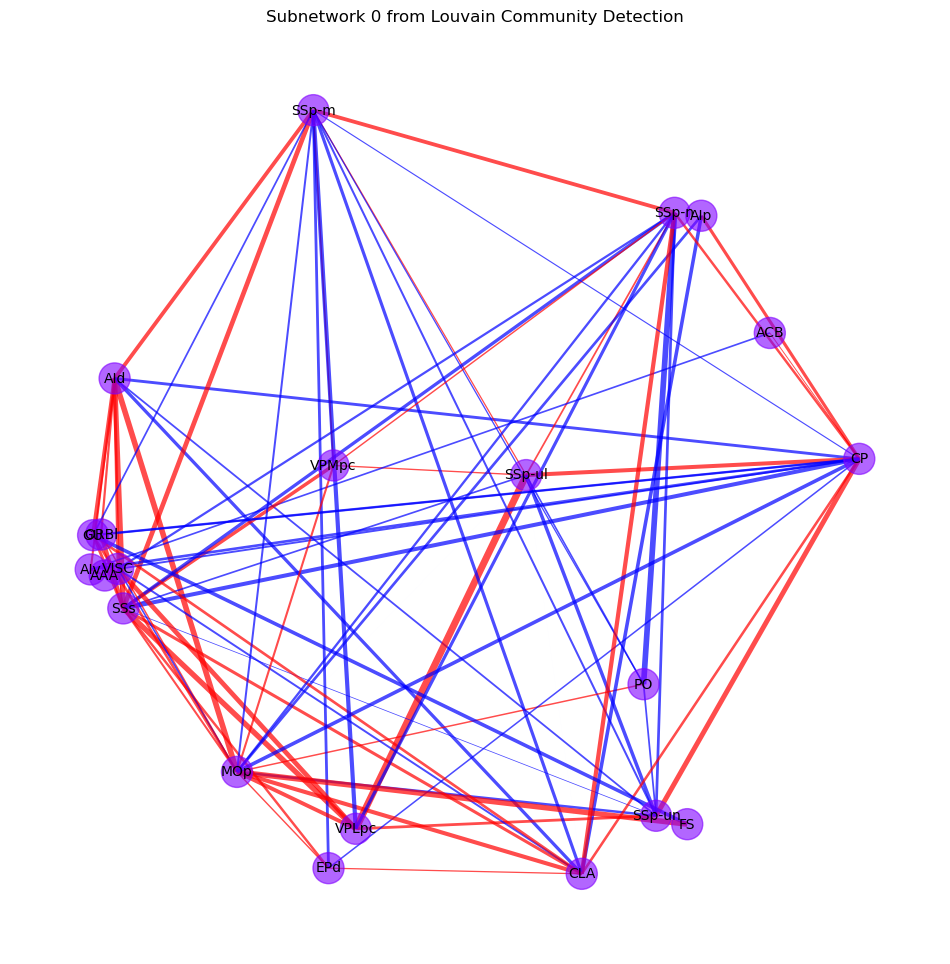

In [86]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def create_filtered_network(Wts, region_names, weight_percentile=90, top_percent=0.1):
    G = nx.Graph()

    # 统计每个连接的出现次数和总权重
    edge_weights = {}
    edge_occurrences = {}

    for t in range(len(Wts)):
        W = Wts[t].copy()
        np.fill_diagonal(W, 0.0)

        # 计算当前图中的权重分布的百分位数
        weight_values = W[W != 0]  # 获取所有非零的权重值
        if len(weight_values) == 0:
            continue
        
        # 计算当前帧中的百分位数阈值
        weight_threshold = np.percentile(weight_values, weight_percentile)

        for i in range(R):
            for j in range(i + 1, R):
                weight = W[i, j]
                edge = (region_names[i], region_names[j])

                if abs(weight) >= weight_threshold:  # 根据当前帧的阈值来保留连接
                    if edge not in edge_weights:
                        edge_weights[edge] = 0
                        edge_occurrences[edge] = 0
                    edge_weights[edge] += weight
                    edge_occurrences[edge] += 1

    # 对连接按权重排序，选择前 top_percent 百分比的最强连接
    strong_edges = []
    for edge in edge_weights:
        total_weight = edge_weights[edge]
        strong_edges.append((edge, total_weight))

    strong_edges = sorted(strong_edges, key=lambda x: abs(x[1]), reverse=True)
    top_n_edges = strong_edges[:int(len(strong_edges) * top_percent)]

    # 将筛选后的连接添加到图中
    for edge, weight in top_n_edges:
        if weight > 0:
            G.add_edge(edge[0], edge[1], weight=weight, sign='positive')
        else:
            G.add_edge(edge[0], edge[1], weight=weight, sign='negative')

    # 删除没有连接的节点
    G.remove_nodes_from(list(nx.isolates(G)))

    return G

def evaluate_subnetworks(G):
    # 使用 greedy_modularity_communities 进行社区检测
    communities = list(nx.algorithms.community.greedy_modularity_communities(G))

    # 确保每个子网络包含所有节点，并计算每个子网络的模块度和总连接强度
    subnetworks = []
    for i, community in enumerate(communities):
        subgraph = G.subgraph(community)
        
        # 计算子网络的模块度
        modularity = nx.community.modularity(G, communities)  # 直接传递 communities，而不是嵌套列表
        
        # 计算子网络的总连接强度（所有边的权重和）
        total_weight = sum([G[u][v]['weight'] for u, v in subgraph.edges()])
        
        subnetworks.append({
            'index': i,
            'modularity': modularity,
            'total_weight': total_weight,
            'size': len(community),
            'community': community  # 保存每个社区的节点
        })

    # 根据模块度和总连接强度进行排序
    subnetworks = sorted(subnetworks, key=lambda x: (x['modularity'], x['total_weight']), reverse=True)

    return subnetworks

def plot_subnetwork(G, community_idx, title):
    # 使用 greedy_modularity_communities 进行社区检测
    communities = list(nx.algorithms.community.greedy_modularity_communities(G))

    # 获取指定社区的子图
    selected_community = communities[community_idx]
    subnetwork = G.subgraph(selected_community).copy()

    # 获取边的颜色和粗细
    edge_colors = ['r' if subnetwork[u][v]['sign'] == 'positive' else 'b' for u, v in subnetwork.edges()]
    edge_widths = [abs(subnetwork[u][v]['weight']) / max(abs(subnetwork[u][v]['weight']) for u, v in subnetwork.edges()) * 5 for u, v in subnetwork.edges()]

    # 获取节点颜色（每个社区一个颜色）
    node_colors = [community_idx for _ in subnetwork.nodes()]

    # 绘制子网络
    pos = nx.spring_layout(subnetwork, seed=42, k=1.0, iterations=100)  # 设置布局
    plt.figure(figsize=(12, 12))
    
    # 绘制节点和边
    nx.draw_networkx_nodes(subnetwork, pos, node_size=500, node_color=node_colors, cmap=plt.cm.rainbow, alpha=0.6)
    nx.draw_networkx_edges(subnetwork, pos, edge_color=edge_colors, width=edge_widths, alpha=0.7)
    nx.draw_networkx_labels(subnetwork, pos, font_size=10, font_color='black')
    
    plt.title(title)
    plt.axis('off')
    plt.show()

# ====== 生成并绘制Louvain社区检测后的子网 ======
weight_percentile = 50  # 使用50%的百分位数来筛选边
top_percent = 1  # 保留前100%的强连接

G_filtered = create_filtered_network(Wts, region_names, weight_percentile, top_percent)

# 评估子网络的模块度和总连接强度
subnetworks = evaluate_subnetworks(G_filtered)

# 打印出每个子网络的评估信息
for sn in subnetworks:
    print(f"Subnetwork {sn['index']}: Modularity={sn['modularity']:.4f}, Total Weight={sn['total_weight']:.2f}, Size={sn['size']}")

# 选择显示某个子网络（比如显示模块度最高的子网络）
community_idx = subnetworks[1]['index']  # 选择模块度最高的子网络
plot_subnetwork(G_filtered, community_idx, f"Subnetwork {community_idx} from Louvain Community Detection")


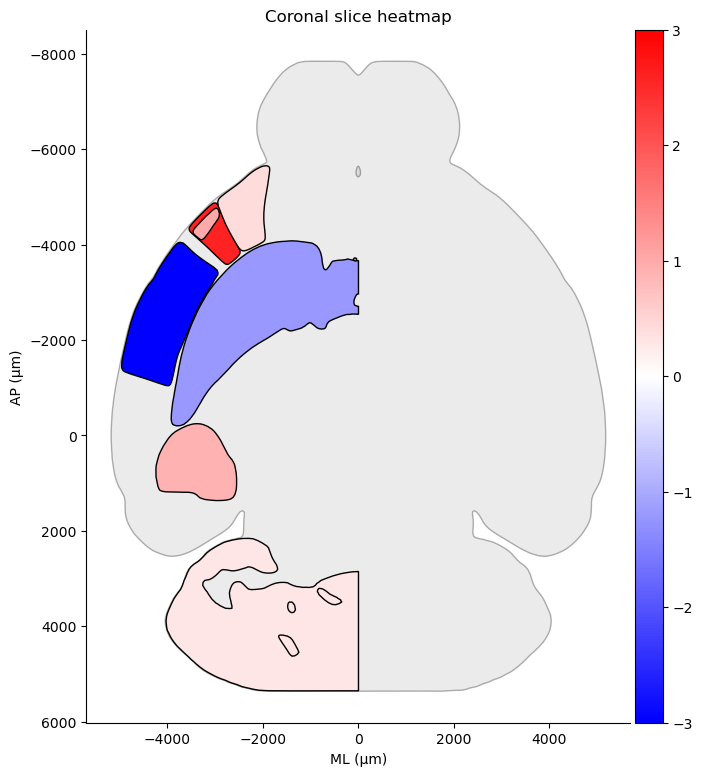

In [48]:
import brainglobe_heatmap as bgh

values = {
    "MOp2/3": 1.0, "RSP": 0.2, "AI": 0.4, "SS": -3.0, "MO": 2.6,
    "VIS": 1.8, "HIP": 0.9, "STR": -1.2, "CB": 0.3,
}

# 正确写法
fig = bgh.Heatmap(
    values=values,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=-3, vmax=3,
    cmap="bwr",
    format="2D",  
    atlas_name="allen_mouse_25um",
    title="Coronal slice heatmap",
).show(xlabel='ML (μm)', ylabel='AP (μm)')

#("frontal", 8000, 1500, "Coronal"),
#("sagittal", 6000, 1500, "Sagittal"),
#("horizontal", 4000, 1500, "Horizontal")


In [47]:
import brainglobe_heatmap as bgh

values = {
    "TH": 1.0, "RSP": 0.2, "AI": 0.4, "SS": -3.0, "MO": 2.6,
    "VIS": 1.8, "HIP": 0.9, "STR": -1.2, "CB": 0.3,
}

# 创建热图
heatmap = bgh.Heatmap(
    values=values,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=-3, vmax=3,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Coronal slice heatmap",
)

# 不直接 show，而是获取 plotter 对象
plotter = heatmap.plotter

# 显示一次图像（必要，否则截图为空）
plotter.show(interactive=False)

# 保存截图
plotter.screenshot("coronal_slice_heatmap.png")

# 关闭窗口
plotter.close()


AttributeError: 'Heatmap' object has no attribute 'plotter'

In [7]:
from brainglobe_atlasapi import BrainGlobeAtlas
import numpy as np

atlas = BrainGlobeAtlas("allen_mouse_25um")

# 1️⃣ 获取 SSp 区域 mask
mask = atlas.get_structure_mask("SSp")

# 2️⃣ 提取左半脑
midline = mask.shape[0] // 2
left_mask = mask[:midline, :, :]

# 3️⃣ 计算质心体素坐标
coords = np.argwhere(left_mask)
centroid_voxel = coords.mean(axis=0)  # [z, y, x]

# 4️⃣ 转换为 µm 空间坐标
resolution = np.array(atlas.resolution)  # [z, y, x] 每个方向 µm/voxel
centroid_um = centroid_voxel * resolution

print("SSp 左半脑质心 (voxel index):", centroid_voxel)
print("SSp 左半脑质心 (μm):", centroid_um)


SSp 左半脑质心 (voxel index): [217.22236528  87.54100387 227.7192513 ]
SSp 左半脑质心 (μm): [5430.55913209 2188.52509685 5692.98128246]


SSp左半脑质心: ML=-2975.6, AP=-861.1, DV=-1942.3


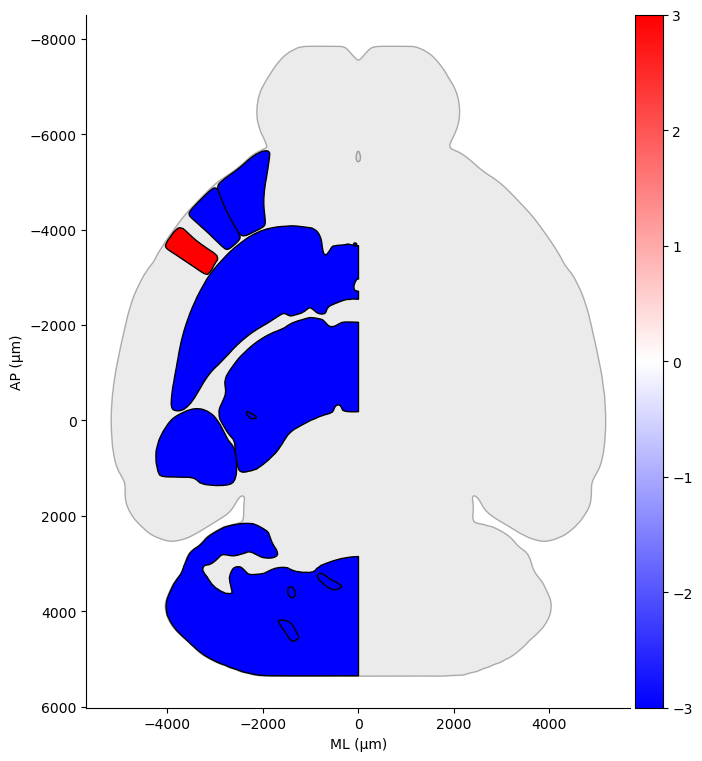

✅ 已保存 brain_slice.png（非空）
✅ 已生成 overlay.png（脑切片 + 质心叠合）
正在现有浏览器会话中打开。


In [42]:
import brainglobe_heatmap as bgh
from brainglobe_atlasapi import BrainGlobeAtlas
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# === 1️⃣ Atlas & 质心 ===
atlas = BrainGlobeAtlas("allen_mouse_25um")
mask = atlas.get_structure_mask("SSp")
z, y, x = mask.shape
coords = np.argwhere(mask[:, :, :x//2])
centroid_voxel = coords.mean(axis=0)
res = np.array(atlas.resolution)
extent = np.array(mask.shape) * res
ap_c = centroid_voxel[0]*res[0] - extent[0]/2
dv_c = centroid_voxel[1]*res[1] - extent[1]/2
ml_c = centroid_voxel[2]*res[2] - extent[2]/2
print(f"SSp左半脑质心: ML={ml_c:.1f}, AP={ap_c:.1f}, DV={dv_c:.1f}")

# === 2️⃣ 绘制脑切片图 ===
heatmap = bgh.Heatmap(
    values={"TH": -3, "RSP": -3, "AI": -3, "SSp": 3, "MO": -3,
            "VIS": -3, "HIP": -3, "STR": -3, "CB": -3},
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=-3, vmax=3,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title=None,
)

# === 3️⃣ 手动保存当前 figure（必须紧跟 plot）===
fig = heatmap.plot(xlabel="ML (μm)", ylabel="AP (μm)")
fig = plt.gcf()  # 捕获当前激活的 figure
fig.savefig("brain_slice.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)
print("✅ 已保存 brain_slice.png（非空）")

# === 4️⃣ 用 PIL 叠加质心点 ===
base = Image.open("brain_slice.png").convert("RGBA")
draw = ImageDraw.Draw(base)

# 简单坐标映射（经验范围，足够用于展示）
def map_to_pixel(value, vmin, vmax, pixels, invert=False):
    ratio = (value - vmin) / (vmax - vmin)
    ratio = np.clip(ratio, 0, 1)
    if invert:
        ratio = 1 - ratio
    return int(ratio * pixels)

# 映射到像素坐标（根据脑的典型范围）
x_pix = map_to_pixel(ml_c, -6000, 0, base.width)
y_pix = map_to_pixel(ap_c, -6000, 6000, base.height, invert=True)

# 画出质心圆与文字
r = 10
draw.ellipse((x_pix - r, y_pix - r, x_pix + r, y_pix + r),
             fill="yellow", outline="black", width=3)
draw.text((x_pix + 15, y_pix - 10), "SSp centroid", fill="black")

base.save("overlay.png")
base.show()
print("✅ 已生成 overlay.png（脑切片 + 质心叠合）")


In [38]:
from PIL import Image, ImageDraw, ImageFont
import numpy as np

# === 1️⃣ 输入部分 ===
# 你的脑切面图路径
brain_slice_path = "brain_slice.png"

# 输出路径
output_path = "overlay_final.png"

# 质心坐标（单位 μm）——你已有这三个变量
ml_c = -2500    # 左负右正
ap_c = 1200     # 前正后负
# ⚠️ DV 坐标不重要，因为我们叠加在固定切面上

# 图像尺寸和脑图对应范围（与 allen_mouse_25um 对齐）
# 如果你用 Heatmap format="2D"，横轴是 ML，纵轴是 AP。
# 下面是假设值：ML ∈ [-5500, 0], AP ∈ [-6000, 6000]
extent_ml = (-5500, 0)
extent_ap = (-6000, 6000)

# === 2️⃣ 读取脑切面图 ===
img = Image.open(brain_slice_path).convert("RGBA")
W, H = img.size

# === 3️⃣ 将 μm 坐标映射到像素坐标 ===
def map_to_pixel(value, vmin, vmax, pixels, invert=False):
    """将 μm 坐标映射为像素位置"""
    ratio = (value - vmin) / (vmax - vmin)
    if invert:
        ratio = 1 - ratio
    return int(ratio * pixels)

x_pix = map_to_pixel(ml_c, extent_ml[0], extent_ml[1], W)  # ML → x
y_pix = map_to_pixel(ap_c, extent_ap[0], extent_ap[1], H, invert=True)  # AP → y (倒置显示)

# === 4️⃣ 叠加质心标记 ===
draw = ImageDraw.Draw(img)
r = 10  # 半径
draw.ellipse((x_pix - r, y_pix - r, x_pix + r, y_pix + r),
             fill="yellow", outline="black", width=3)
draw.text((x_pix + 15, y_pix - 10), "SSp centroid", fill="black")

# === 5️⃣ 保存并显示 ===
img.save(output_path)
print(f"✅ 叠加完成：{output_path}")
img.show()


✅ 叠加完成：overlay_final.png
正在现有浏览器会话中打开。
